In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [17]:
precision_weight = 0.20
recall_weight = 0.50
f1_weight = 0.30

In [18]:
def manual_metrics(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)

    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    specificity = tn / (tn + fp) if tn + fp else 0

    custom_score = (
        precision_weight * precision
        + recall_weight * recall
        + f1_weight * f1
    )

    return {
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Specificity": specificity,
        "Custom score": custom_score,
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn
    }

In [19]:
import os

for root, dirs, files in os.walk("."):
    dirs[:] = [
        d for d in dirs
        if d not in {".git", "__pycache__", ".venv", "venv"}
    ]

    for file in files:
        if file.endswith(".py"):
            print(os.path.join(root, file))

./app.py


In [20]:
if "test_predictions" not in globals():
    raise ValueError(
        "Create test_predictions with your actual model predictions."
    )

if "y_test" not in globals():
    raise ValueError("Define y_test for the common test set.")

rows = []

for model_name, predictions in test_predictions.items():
    if len(predictions) != len(y_test):
        raise ValueError(
            f"{model_name} does not match the test-set size."
        )

    rows.append({
        "Model": model_name,
        **manual_metrics(y_test, predictions)
    })

results = pd.DataFrame(rows)
results = results.sort_values(
    "Custom score", ascending=False
).reset_index(drop=True)

print("MODEL PERFORMANCE RANKING")
print(results.round(4).to_string(index=False))

best_model = results.iloc[0]

print("\nSELECTED MODEL:", best_model["Model"])
print(f"Precision: {best_model['Precision']:.4f}")
print(f"Recall: {best_model['Recall']:.4f}")
print(f"F1-score: {best_model['F1-score']:.4f}")
print(f"Custom score: {best_model['Custom score']:.4f}")

results.to_csv(
    "best_model_performance_analysis.csv",
    index=False
)

MODEL PERFORMANCE RANKING
              Model  Precision  Recall  F1-score  Specificity  Custom score  TP  TN  FP  FN
Logistic Regression     0.8824  0.8824    0.8824       0.8621        0.8824  30  25   4   4
               k-NN     0.8824  0.8824    0.8824       0.8621        0.8824  30  25   4   4
      Decision Tree     0.8065  0.7353    0.7692       0.7931        0.7597  25  23   6   9

SELECTED MODEL: Logistic Regression
Precision: 0.8824
Recall: 0.8824
F1-score: 0.8824
Custom score: 0.8824


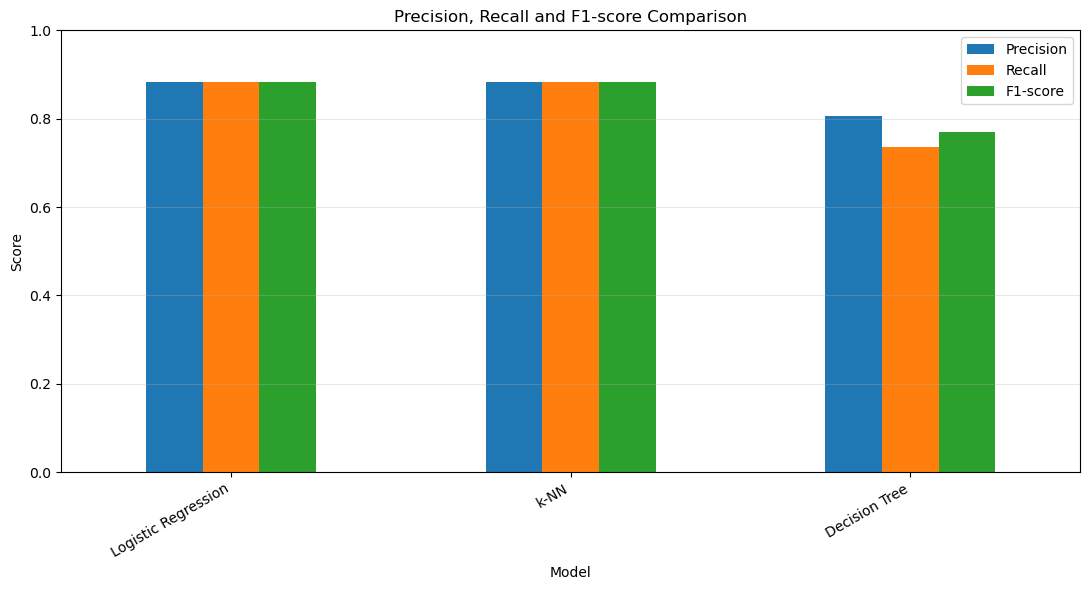

In [21]:
results.set_index("Model")[
    ["Precision", "Recall", "F1-score"]
].plot(kind="bar", figsize=(11, 6))

plt.title("Precision, Recall and F1-score Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
